# Kiểm tra dữ liệu — TV1
Chuyển 5 bước đã chạy vào đây hoặc gọi src.data sau khi hoàn thành. Chưa có data/output trong notebook khung.

In [9]:


import torch
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Chuyển ảnh thành tensor để PyTorch xử lý.
transform = transforms.ToTensor()

# Tập dùng cho huấn luyện và tách validation.
full_train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Tập kiểm tra cuối cùng.
test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

class_names = full_train_dataset.classes

print("Số ảnh train ban đầu:", len(full_train_dataset))
print("Số ảnh test:", len(test_dataset))
print("Tên các lớp:", class_names)


Số ảnh train ban đầu: 60000
Số ảnh test: 10000
Tên các lớp: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


TEST 1 ẢNH VÀ 1 NHÃN BẤT KÌ XEM DỮ LIỆU ĐÃ CHẠY ĐC CHƯA


Kích thước ảnh: torch.Size([1, 28, 28])
Kiểu dữ liệu ảnh: torch.float32
Pixel nhỏ nhất: 0.0
Pixel lớn nhất: 1.0
Nhãn số: 9
Tên lớp: Ankle boot


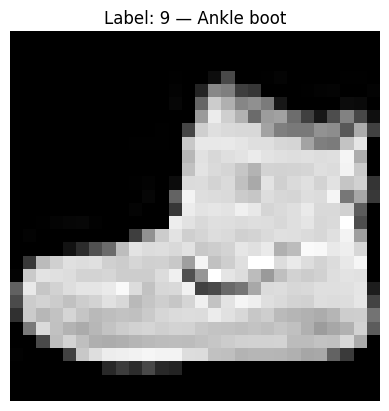

In [10]:
image, label = full_train_dataset[0]

print("Kích thước ảnh:", image.shape)
print("Kiểu dữ liệu ảnh:", image.dtype)
print("Pixel nhỏ nhất:", image.min().item())
print("Pixel lớn nhất:", image.max().item())
print("Nhãn số:", label)
print("Tên lớp:", class_names[label])

plt.imshow(image.squeeze(0), cmap="gray")
plt.title(f"Label: {label} — {class_names[label]}")
plt.axis("off")
plt.show()

Xem nhiều ảnh để hiểu data

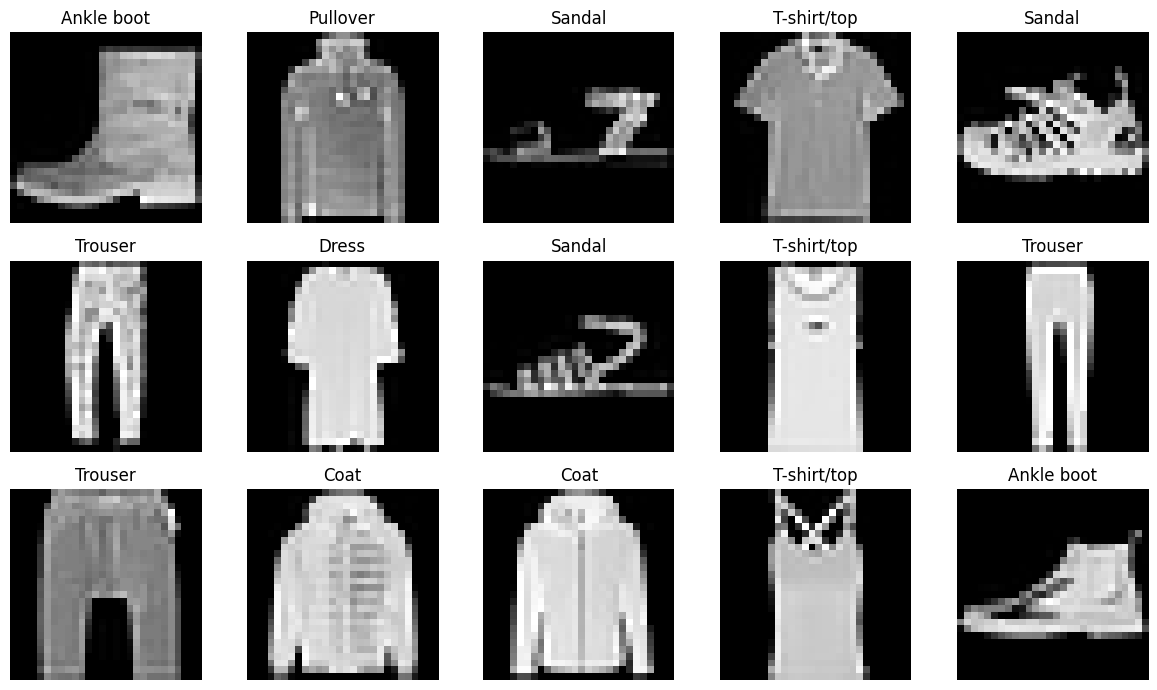

In [11]:
fig, axes = plt.subplots(3, 5, figsize=(12, 7))

generator = torch.Generator().manual_seed(42)
indices = torch.randperm(
    len(full_train_dataset),
    generator=generator
)[:15]

for ax, index in zip(axes.flat, indices.tolist()):
    image, label = full_train_dataset[index]

    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

Thử chia train và test ( lưu ý đây chỉ là thực nghiệm)

In [12]:
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [54000, 6000],
    generator=torch.Generator().manual_seed(42)
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 54000
Validation: 6000
Test: 10000


Gom ảnh thành batch bằng DataLoader


In [13]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("Kích thước batch ảnh:", images.shape)
print("Kích thước batch nhãn:", labels.shape)
print("Kiểu nhãn:", labels.dtype)

Kích thước batch ảnh: torch.Size([64, 1, 28, 28])
Kích thước batch nhãn: torch.Size([64])
Kiểu nhãn: torch.int64


T-shirt/top: 6000 ảnh
Trouser: 6000 ảnh
Pullover: 6000 ảnh
Dress: 6000 ảnh
Coat: 6000 ảnh
Sandal: 6000 ảnh
Shirt: 6000 ảnh
Sneaker: 6000 ảnh
Bag: 6000 ảnh
Ankle boot: 6000 ảnh


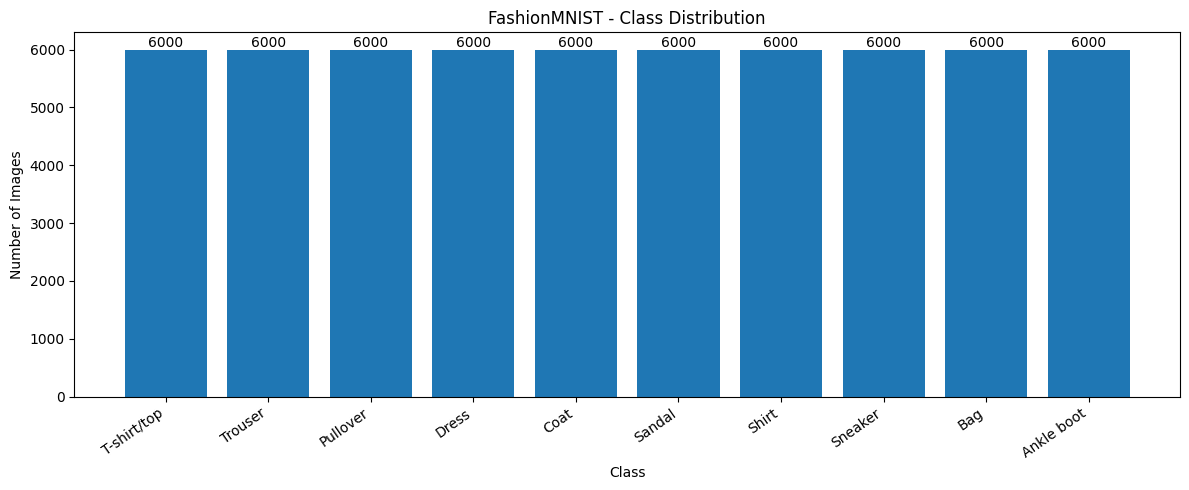

In [8]:
# EDA 1: Phân bố số lượng ảnh theo 10 lớp FashionMNIST

import torch
import matplotlib.pyplot as plt

# Đếm số ảnh của từng lớp
class_counts = torch.bincount(
    full_train_dataset.targets,
    minlength=10
)

# In số lượng ảnh từng lớp
for i, class_name in enumerate(class_names):
    print(f"{class_name}: {class_counts[i].item()} ảnh")

# Vẽ biểu đồ
plt.figure(figsize=(12, 5))

bars = plt.bar(
    class_names,
    class_counts.numpy()
)

plt.title("FashionMNIST - Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=35, ha="right")

# Hiển thị số lượng trên từng cột
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

Tổng số pixel: 47040000
Giá trị pixel nhỏ nhất: 0
Giá trị pixel lớn nhất: 255


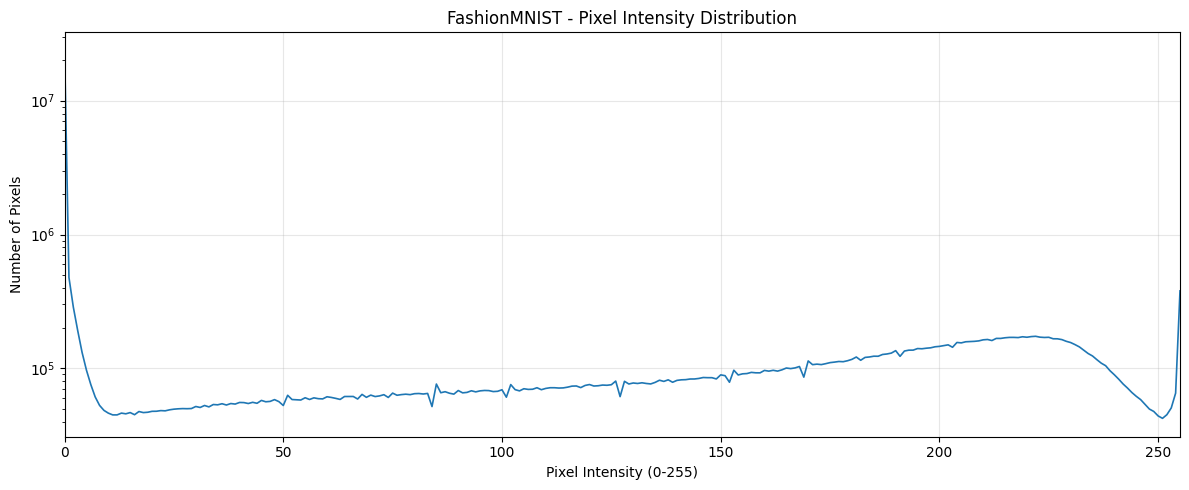

In [14]:

# EDA 2: Histogram phân bố giá trị Pixel FashionMNIST

import torch
import matplotlib.pyplot as plt

# Lấy dữ liệu ảnh gốc (giá trị pixel từ 0 đến 255)
pixel_data = full_train_dataset.data

# Tính histogram theo từng nhóm ảnh để tiết kiệm bộ nhớ
hist_counts = torch.zeros(256, dtype=torch.float64)

for start in range(0, len(pixel_data), 5000):
    batch_pixels = pixel_data[start:start + 5000].float()

    batch_hist = torch.histc(
        batch_pixels,
        bins=256,
        min=0,
        max=255
    )

    hist_counts += batch_hist.double()

# In thông tin tổng quan
print("Tổng số pixel:", int(hist_counts.sum().item()))
print("Giá trị pixel nhỏ nhất:", pixel_data.min().item())
print("Giá trị pixel lớn nhất:", pixel_data.max().item())

# Vẽ histogram
plt.figure(figsize=(12, 5))

plt.plot(
    range(256),
    hist_counts.numpy(),
    linewidth=1.2
)

plt.title("FashionMNIST - Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Number of Pixels")

plt.yscale("log")
plt.xlim(0, 255)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Kích thước dữ liệu ban đầu: (5000, 784)
Explained variance PC1: 28.75 %
Explained variance PC2: 17.95 %
Tổng phương sai được giải thích: 46.7 %
Kích thước sau PCA: (5000, 2)


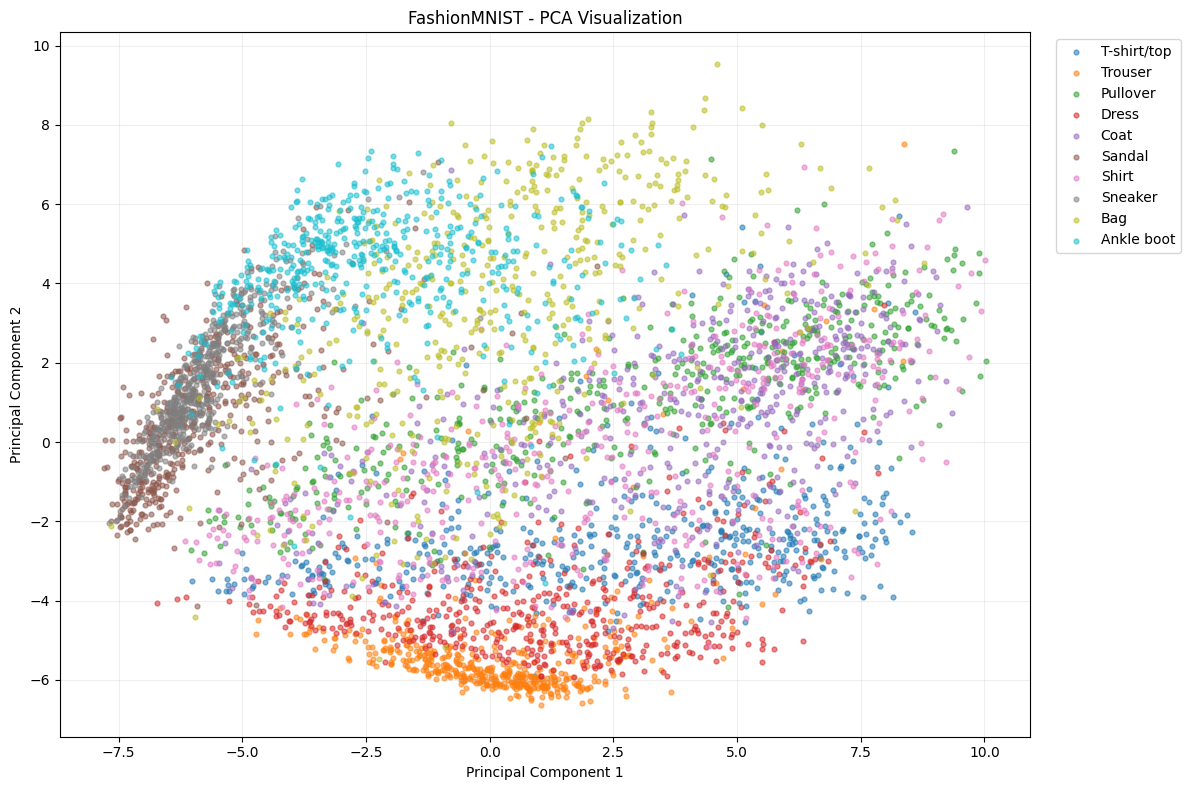

In [15]:

# EDA 3: PCA - Giảm chiều dữ liệu FashionMNIST từ 784 xuống 2

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Cố định ngẫu nhiên để có thể tái lập kết quả
generator = torch.Generator().manual_seed(42)

# Lấy 500 ảnh ngẫu nhiên từ mỗi lớp
sample_indices = []

for label in range(10):
    indices = torch.where(
        full_train_dataset.targets == label
    )[0]

    selected = torch.randperm(
        len(indices),
        generator=generator
    )[:500]

    sample_indices.append(indices[selected])

sample_indices = torch.cat(sample_indices)

# Chuyển ảnh về dạng vector 784 chiều
images = full_train_dataset.data[sample_indices]
images = images.float() / 255.0
X = images.reshape(len(images), 784).numpy()

# Lấy nhãn tương ứng
y = full_train_dataset.targets[sample_indices].numpy()

print("Kích thước dữ liệu ban đầu:", X.shape)

# Thực hiện PCA giảm xuống 2 chiều
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

# In tỷ lệ phương sai được giải thích
print("Explained variance PC1:",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("Explained variance PC2:",
      round(pca.explained_variance_ratio_[1] * 100, 2), "%")

print("Tổng phương sai được giải thích:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

print("Kích thước sau PCA:", X_pca.shape)

# Vẽ biểu đồ PCA
plt.figure(figsize=(12, 8))

for label in range(10):
    mask = y == label

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=12,
        alpha=0.55,
        label=class_names[label]
    )

plt.title("FashionMNIST - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()



## 4. Nhận xét và kết luận EDA

### 4.1. Phân bố dữ liệu

FashionMNIST có 60.000 ảnh trong tập train ban đầu và 10 lớp phân loại. Mỗi lớp có 6.000 ảnh, cho thấy dữ liệu được phân bố đồng đều giữa các lớp. Vì vậy, tập dữ liệu không có sự mất cân bằng về số lượng mẫu giữa các lớp.

### 4.2. Phân bố giá trị Pixel

Histogram cho thấy giá trị pixel trải dài từ 0 đến 255. Số lượng pixel có giá trị bằng 0 chiếm phần lớn do nền ảnh FashionMNIST chủ yếu có màu đen. Các pixel có giá trị cao hơn chủ yếu thể hiện vùng hình ảnh quần áo với mức độ sáng khác nhau.

### 4.3. Phân tích PCA

PCA được thực hiện trên 5.000 ảnh, lấy 500 ảnh cho mỗi lớp. Dữ liệu ban đầu có 784 đặc trưng và được giảm xuống còn 2 thành phần chính.

PC1 giải thích 28,75% phương sai, PC2 giải thích 17,95%. Tổng phương sai được giải thích là 46,70%.

Biểu đồ cho thấy một số lớp có xu hướng tạo thành các vùng phân bố riêng, tuy nhiên vẫn tồn tại sự chồng lấn giữa nhiều lớp. Điều này cho thấy hai thành phần chính chưa thể giữ lại toàn bộ thông tin cần thiết để phân biệt các loại quần áo.

### 4.4. Kết luận

Qua quá trình EDA, nhóm nhận thấy FashionMNIST có dữ liệu cân bằng giữa 10 lớp, ảnh grayscale có kích thước 28×28 pixel và giá trị pixel nằm trong khoảng 0–255.

Histogram giúp quan sát đặc điểm độ sáng của ảnh, trong khi PCA hỗ trợ trực quan hóa sự phân bố dữ liệu trong không gian hai chiều. Những kết quả này cung cấp cái nhìn tổng quan về dữ liệu trước khi đưa vào xây dựng và huấn luyện mô hình phân loại.
